## Learning Objective: Bahdanau Attention in Sequence-to-Sequence (Seq2Seq) Models

By the end of this lab segment, you will understand and implement Neural Machine Translation (NMT) using an Encoder-Decoder architecture enhanced with Bahdanau (Additive) Attention, 

- The Seq2Seq Paradigm: How to encode a variable-length input sequence (e.g., English) into hidden states and decode it step-by-step into a target sequence (e.g., Spanish).

- Overcoming the Bottleneck: Why fixed-length context vectors fail on long sentences, and how dynamic attention allows the decoder to "look back" at specific input tokens dynamically.

- Alignment & Interpretability: How attention weights form an alignment matrix (heatmap) that visually proves which source words the model focuses on when generating each translated word.

- Evaluation & Generation: How to inspect generated translations token-by-token, handle token mapping, and evaluate model performance on unseen test sentences.

In [1]:
## Step 0: :oading Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import unicodedata
import re
import io
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Verify TensorFlow version and GPU availability
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", "Yes" if tf.config.list_physical_devices('GPU') else "No (Running on CPU)")
print("\nAll required libraries loaded successfully!")

TensorFlow Version: 2.21.0
GPU Available: No (Running on CPU)

All required libraries loaded successfully!


## Load Dataset:
The standard dataset used for this exact TensorFlow/Keras tutorial is the Anki English-Spanish dataset hosted by TensorFlow, which contains over 100,000 real human translation pairs. We can download it automatically and slice out 10,000 samples for fast local training.

In [3]:
import os

# Define your local directory path
data_dir = r"D:\Umesh-MAY2022\Datasets_Research\EngSpanishData\spa-eng"
file_path = os.path.join(data_dir, "spa.txt")

print("Checking file path:", file_path)
print("File exists?", os.path.exists(file_path))

if os.path.exists(file_path):
    # Read the first 5 raw lines from the file
    with open(file_path, 'r', encoding='UTF-8') as f:
        raw_lines = [f.readline().strip() for _ in range(5)]
    
    print("\nFirst 5 raw lines from spa.txt:")
    for idx, line in enumerate(raw_lines, 1):
        print(f"  {idx}: {line}")
else:
    print("❌ Error: Could not find spa.txt at that path. Please check the folder name.")

Checking file path: D:\Umesh-MAY2022\Datasets_Research\EngSpanishData\spa-eng\spa.txt
File exists? True

First 5 raw lines from spa.txt:
  1: Go.	Ve.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #4986655 (cueyayotl)
  2: Go.	Vete.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #4986656 (cueyayotl)
  3: Go.	Vaya.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #4986657 (cueyayotl)
  4: Go.	Váyase.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #6586271 (arh)
  5: Go.	Id.	CC-BY 2.0 (France) Attribution: tatoeba.org #2877272 (CM) & #13703671 (Seael)


In [4]:
import os

# Define your exact local path
data_dir = r"D:\Umesh-MAY2022\Datasets_Research\EngSpanishData\spa-eng"
file_path = os.path.join(data_dir, "spa.txt")

num_examples = 10000
en_sentences = []
es_sentences = []

# Read the file and parse lines
with open(file_path, 'r', encoding='UTF-8') as f:
    lines = f.read().strip().split('\n')

for line in lines[:num_examples]:
    parts = line.split('\t')
    if len(parts) >= 2:
        en_sentences.append(parts[0])
        es_sentences.append(parts[1])

print(f"Successfully loaded {len(en_sentences)} sentence pairs from local storage!")
print(f"\nSample Pair #1:")
print(f"  English (Input) : {en_sentences[0]}")
print(f"  Spanish (Target): {es_sentences[0]}")

print(f"\nSample Pair #5000:")
print(f"  English (Input) : {en_sentences[4999]}")
print(f"  Spanish (Target): {es_sentences[4999]}")

Successfully loaded 10000 sentence pairs from local storage!

Sample Pair #1:
  English (Input) : Go.
  Spanish (Target): Ve.

Sample Pair #5000:
  English (Input) : Are you drunk?
  Spanish (Target): ¿Estás borracho?


## Text Preprocessing and Cleaning
Before feeding these sentences into our tokenizers, we need to normalize them. 
This step converts all text to lowercase, removes accent marks (e.g., turning accented characters into standard ASCII), adds spaces around punctuation so tokenizers don't merge words with punctuation marks, and wraps every target sentence with <start> and <end> tokens so the decoder knows where to begin and stop generating.

In [5]:
import unicodedata
import re

print("--- Step 1.3: Text Preprocessing and Cleaning ---")

def unicode_to_ascii(s):
    # Normalize unicode characters and remove accent marks
    return ''.join(c for c in unicodedata.normalize('NFD', s)
                   if unicodedata.category(c) != 'Mn')

def preprocess_sentence(w):
    # 1. Lowercase and remove accents
    w = unicode_to_ascii(w.lower().strip())
    
    # 2. Put a space between a word and the punctuation following it (e.g., "help!" -> "help !")
    w = re.sub(r"([?.!,¿])", r" \1 ", w)
    w = re.sub(r'[" "]+', " ", w)
    
    # 3. Replace everything with space except letters and basic punctuation
    w = re.sub(r"[^a-zA-Z?.!,¿]+", " ", w)
    w = w.strip()
    
    # 4. Add start and end tokens for the decoder
    w = '<start> ' + w + ' <end>'
    return w

# Apply cleaning to all 10,000 sentences
en_sentences_cleaned = [preprocess_sentence(en) for en in en_sentences]
es_sentences_cleaned = [preprocess_sentence(es) for es in es_sentences]

# Print sample before and after cleaning
print("\nBefore Cleaning (Sample #5000):")
print(f"  EN: {en_sentences[4999]}")
print(f"  ES: {es_sentences[4999]}")

print("\nAfter Preprocessing & Token Wrapper (Sample #5000):")
print(f"  EN: {en_sentences_cleaned[4999]}")
print(f"  ES: {es_sentences_cleaned[4999]}")

--- Step 1.3: Text Preprocessing and Cleaning ---

Before Cleaning (Sample #5000):
  EN: Are you drunk?
  ES: ¿Estás borracho?

After Preprocessing & Token Wrapper (Sample #5000):
  EN: <start> are you drunk ? <end>
  ES: <start> ¿ estas borracho ? <end>


## Step 2: Tokenization and Padding
Now that our text data is cleaned, we need to convert words into numerical integer tokens so the neural network can process them. We will use TensorFlow's Tokenizer to build vocabulary dictionaries for both English and Spanish, convert our sentences into integer sequences, and pad them to a uniform length.

In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("--- Step 2: Tokenization and Padding ---")

def tokenize(lang):
    # Initialize tokenizer without default filters so our tags like <start> and <end> are preserved
    lang_tokenizer = Tokenizer(filters='')
    lang_tokenizer.fit_on_texts(lang)
    
    # Convert text to sequences of integers
    tensor = lang_tokenizer.texts_to_sequences(lang)
    
    # Pad sequences to ensure uniform length for batch training
    tensor = pad_sequences(tensor, padding='post')
    
    return tensor, lang_tokenizer

# Tokenize English and Spanish datasets
input_tensor, input_tokenizer = tokenize(en_sentences_cleaned)
target_tensor, target_tokenizer = tokenize(es_sentences_cleaned)

# Determine maximum sequence lengths
max_length_inp = input_tensor.shape[1]
max_length_targ = target_tensor.shape[1]

print(f"English Vocabulary Size : {len(input_tokenizer.word_index)}")
print(f"Spanish Vocabulary Size : {len(target_tokenizer.word_index)}")
print(f"Max English Sequence Len: {max_length_inp}")
print(f"Max Spanish Sequence Len: {max_length_targ}")

# Inspect tokenized representation for Sample #5000 ("Are you drunk?")
print(f"\nSample #5000 Inspection:")
print(f"  EN Text : {en_sentences_cleaned[4999]}")
print(f"  EN Token: {input_tensor[4999]}")
print(f"  ES Text : {es_sentences_cleaned[4999]}")
print(f"  ES Token: {target_tensor[4999]}")

--- Step 2: Tokenization and Padding ---
English Vocabulary Size : 2176
Spanish Vocabulary Size : 4575
Max English Sequence Len: 8
Max Spanish Sequence Len: 13

Sample #5000 Inspection:
  EN Text : <start> are you drunk ? <end>
  EN Token: [  1  22   8 163   6   2   0   0]
  ES Text : <start> ¿ estas borracho ? <end>
  ES Token: [  1   5  35 237   4   2   0   0   0   0   0   0   0]


## Step 3: Creating Training Batches & Train-Test Split
Now that our data is tokenized and padded, we will split our 10,000 sentence pairs into training and validation sets, and wrap them into TensorFlow tf.data.Dataset objects. This allows us to shuffle and batch our data efficiently for training.
                                                                                                                                                                                                                                     

In [7]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

print("--- Step 3: Train-Test Split and Batching ---")

# 1. Split data into 80% training and 20% validation
input_tensor_train, input_tensor_val, target_tensor_train, target_tensor_val = train_test_split(
    input_tensor, target_tensor, test_size=0.2, random_state=42
)

print(f"Training samples   : {len(input_tensor_train)}")
print(f"Validation samples : {len(input_tensor_val)}")

# 2. Configure training parameters
BUFFER_SIZE = len(input_tensor_train)
BATCH_SIZE = 64
steps_per_epoch = len(input_tensor_train) // BATCH_SIZE
embedding_dim = 256
units = 1024
vocab_inp_size = len(input_tokenizer.word_index) + 1
vocab_tar_size = len(target_tokenizer.word_index) + 1

# 3. Create TensorFlow dataset pipeline
dataset = tf.data.Dataset.from_tensor_slices((input_tensor_train, target_tensor_train)).shuffle(BUFFER_SIZE)
dataset = dataset.batch(BATCH_SIZE, drop_remainder=True)

# Inspect a single batch shape
example_input_batch, example_target_batch = next(iter(dataset))
print(f"\nBatch Shapes:")
print(f"  Input Batch Shape : {example_input_batch.shape}")
print(f"  Target Batch Shape: {example_target_batch.shape}")

--- Step 3: Train-Test Split and Batching ---
Training samples   : 8000
Validation samples : 2000

Batch Shapes:
  Input Batch Shape : (64, 8)
  Target Batch Shape: (64, 13)


## Step 4: Building the Encoder Network
The Encoder takes our padded English token sequences, converts the integer IDs into dense vectors via an Embedding layer, and processes them through a Gated Recurrent Unit (GRU).

Crucially, because we are using Bahdanau Attention, the encoder must return return_sequences=True so that it outputs hidden states for every word in the sentence, not just the final word.

In [9]:
import tensorflow as tf

print("--- Step 4: Building the Encoder Network ---")

class Encoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, enc_units, batch_sz):
        super(Encoder, self).__init__()
        self.batch_sz = batch_sz
        self.enc_units = enc_units
        
        # 1. Embedding layer: maps word integer IDs to dense vectors of embedding_dim
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        
        # 2. GRU layer: processes the sequence and returns outputs + hidden state
        # return_sequences=True and return_state=True are essential for Bahdanau Attention!
        self.gru = tf.keras.layers.GRU(
            self.enc_units,
            return_sequences=True,
            return_state=True,
            recurrent_initializer='glorot_uniform'
        )

    def call(self, x, hidden):
        # x shape: (batch_size, seq_length)
        x = self.embedding(x)
        # output shape: (batch_size, seq_length, enc_units)
        # state shape: (batch_size, enc_units)
        output, state = self.gru(x, initial_state=hidden)
        return output, state

    def initialize_hidden_state(self):
        # Initialize encoder hidden states with zeros for the start of a batch
        return tf.zeros((self.batch_sz, self.enc_units))

# Instantiate the encoder using parameters defined in Step 3
encoder = Encoder(vocab_inp_size, embedding_dim, units, BATCH_SIZE)

# Test the encoder with our sample batch from Step 3
sample_hidden = encoder.initialize_hidden_state()
sample_output, sample_hidden = encoder(example_input_batch, sample_hidden)

print(f"Encoder output shape (batch_size, seq_len, units): {sample_output.shape}")
print(f"Encoder hidden state shape (batch_size, units) : {sample_hidden.shape}")

--- Step 4: Building the Encoder Network ---
Encoder output shape (batch_size, seq_len, units): (64, 8, 1024)
Encoder hidden state shape (batch_size, units) : (64, 1024)


## Step 5: Building Bahdanau Attention and the Decoder Network
Now that we understand how the encoder builds our sequential feature map, let's build the second half of our model: Bahdanau Attention and the Decoder.

Bahdanau Attention: Compares the decoder's current hidden state with all encoder outputs to calculate alignment scores (attention weights), producing a context vector that tells the model where to focus.

Decoder: Takes the context vector combined with the previously generated target word, passes it through its own GRU layer, and outputs logits over our Spanish vocabulary to predict the next word.

In [10]:
import tensorflow as tf

print("--- Step 5: Building Bahdanau Attention and Decoder ---")

class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units):
        super(BahdanauAttention, self).__init__()
        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, query, values):
        # query hidden state shape: (batch_size, hidden_size)
        # values (encoder outputs) shape: (batch_size, max_len, hidden_size)
        
        # Add a time axis to query to calculate score: (batch_size, 1, hidden_size)
        query_with_time_axis = tf.expand_dims(query, 1)

        # Score calculation (Additive Attention)
        # score shape: (batch_size, max_len, 1)
        score = self.V(tf.nn.tanh(self.W1(query_with_time_axis) + self.W2(values)))

        # Attention weights shape: (batch_size, max_len, 1)
        attention_weights = tf.nn.softmax(score, axis=1)

        # Context vector shape after sum over encoder time steps: (batch_size, hidden_size)
        context_vector = attention_weights * values
        context_vector = tf.reduce_sum(context_vector, axis=1)

        return context_vector, attention_weights

class Decoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, dec_units, batch_sz):
        super(Decoder, self).__init__()
        self.batch_sz = batch_sz
        self.dec_units = dec_units
        self.embedding = tf.keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = tf.keras.layers.GRU(
            self.dec_units,
            return_sequences=True,
            return_state=True,
            recurrent_initializer='glorot_uniform'
        )
        self.fc = tf.keras.layers.Dense(vocab_size)

        # Initialize Attention
        self.attention = BahdanauAttention(self.dec_units)

    def call(self, x, hidden, enc_output):
        # enc_output shape: (batch_size, max_len, enc_units)
        context_vector, attention_weights = self.attention(hidden, enc_output)

        # x shape after embedding: (batch_size, 1, embedding_dim)
        x = self.embedding(x)

        # Concatenate context vector and embedded input word: (batch_size, 1, embedding_dim + hidden_size)
        x = tf.concat([tf.expand_dims(context_vector, 1), x], axis=-1)

        # Pass concatenated vector to GRU
        output, state = self.gru(x)

        # Output shape: (batch_size * 1, dec_units)
        output = tf.reshape(output, (-1, output.shape[2]))

        # Output shape: (batch_size, vocab)
        x = self.fc(output)

        return x, state, attention_weights

# Instantiate decoder and attention
vocab_tar_size = len(target_tokenizer.word_index) + 1
decoder = Decoder(vocab_tar_size, embedding_dim, units, BATCH_SIZE)

# Test decoder with sample encoder outputs from Step 4
sample_decoder_output, _, _ = decoder(tf.random.uniform((BATCH_SIZE, 1)), sample_hidden, sample_output)

print(f"Decoder output shape (batch_size, vocab_size): {sample_decoder_output.shape}")

--- Step 5: Building Bahdanau Attention and Decoder ---
Decoder output shape (batch_size, vocab_size): (64, 4576)


## Step 6: Defining Loss Function, Optimizer, and Training Step
Now that both our Encoder and Decoder are built and verified, we need to set up how the model learns. Because our target sentences are padded with zeros to ensure uniform length, we will use a masked loss function so the model isn't penalized for predicting padding tokens. We will also define our custom training step using Teacher Forcing (feeding the true target word into the decoder at each step rather than its own prediction, which speeds up convergence).

In [11]:
import tensorflow as tf

print("--- Step 6: Loss Function, Optimizer, and Training Step ---")

# 1. Initialize Optimizer and Loss Object
optimizer = tf.keras.optimizers.Adam()
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True, reduction='none'
)

def loss_function(real, pred):
    # Mask out padding zeros (0) so they don't count toward loss calculation
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)
    
    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask
    
    return tf.reduce_mean(loss_)

# 2. Training Step Function with Teacher Forcing
@tf.function
def train_step(inp, targ, enc_hidden):
    loss = 0
    
    with tf.GradientTape() as tape:
        # Run Encoder
        enc_output, enc_hidden = encoder(inp, enc_hidden)
        
        dec_hidden = enc_hidden
        
        # Decoder input: start with the <start> token for every sentence in the batch
        dec_input = tf.expand_dims([target_tokenizer.word_index['<start>']] * BATCH_SIZE, 1)
        
        # Teacher Forcing: Feed the target as the next input regardless of model prediction
        for t in range(1, targ.shape[1]):
            predictions, dec_hidden, _ = decoder(dec_input, dec_hidden, enc_output)
            
            loss += loss_function(targ[:, t], predictions)
            
            # Use teacher forcing: next input is the actual target word from the dataset
            dec_input = tf.expand_dims(targ[:, t], 1)
            
    batch_loss = (loss / int(targ.shape[1]))
    
    # Calculate gradients and update model weights
    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, variables)
    optimizer.apply_gradients(zip(gradients, variables))
    
    return batch_loss

print("Loss function, optimizer, and training step defined successfully!")

--- Step 6: Loss Function, Optimizer, and Training Step ---
Loss function, optimizer, and training step defined successfully!


## Training the model



In [12]:
import time

print("--- Step 7: Starting the Training Loop ---")

EPOCHS = 10

for epoch in range(EPOCHS):
    start_time = time.time()
    
    # Initialize encoder hidden state at the start of every epoch
    enc_hidden = encoder.initialize_hidden_state()
    total_loss = 0
    
    # Loop through batches in the dataset
    for (batch, (inp, targ)) in enumerate(dataset.take(steps_per_epoch)):
        batch_loss = train_step(inp, targ, enc_hidden)
        total_loss += batch_loss
        
        # Print progress every 50 batches
        if batch % 50 == 0:
            print(f'Epoch {epoch + 1} | Batch {batch} | Loss: {batch_loss.numpy():.4f}')
            
    # Print average loss for the epoch
    epoch_loss = total_loss / steps_per_epoch
    print(f'--> Epoch {epoch + 1} Finished | Average Loss: {epoch_loss:.4f} | Time: {time.time() - start_time:.2f} sec\n')

print("Training complete!")

--- Step 7: Starting the Training Loop ---
Epoch 1 | Batch 0 | Loss: 3.1809
Epoch 1 | Batch 50 | Loss: 1.6126
Epoch 1 | Batch 100 | Loss: 1.4401
--> Epoch 1 Finished | Average Loss: 1.6675 | Time: 76.28 sec

Epoch 2 | Batch 0 | Loss: 1.2313
Epoch 2 | Batch 50 | Loss: 1.1999
Epoch 2 | Batch 100 | Loss: 1.1284
--> Epoch 2 Finished | Average Loss: 1.2480 | Time: 59.95 sec

Epoch 3 | Batch 0 | Loss: 1.0399
Epoch 3 | Batch 50 | Loss: 1.0752
Epoch 3 | Batch 100 | Loss: 1.0862
--> Epoch 3 Finished | Average Loss: 1.0624 | Time: 60.77 sec

Epoch 4 | Batch 0 | Loss: 0.8917
Epoch 4 | Batch 50 | Loss: 0.9305
Epoch 4 | Batch 100 | Loss: 0.8777
--> Epoch 4 Finished | Average Loss: 0.8991 | Time: 58.52 sec

Epoch 5 | Batch 0 | Loss: 0.8422
Epoch 5 | Batch 50 | Loss: 0.8393
Epoch 5 | Batch 100 | Loss: 0.7785
--> Epoch 5 Finished | Average Loss: 0.7646 | Time: 57.38 sec

Epoch 6 | Batch 0 | Loss: 0.6116
Epoch 6 | Batch 50 | Loss: 0.7377
Epoch 6 | Batch 100 | Loss: 0.6344
--> Epoch 6 Finished | Average

## NMT (Neural Machine Translation): This is the overarching name of the entire project/task we are building (translating English to Spanish using neural networks).

## Step 8: Building the Evaluation and Prediction Function (Inference)
Now that your model is trained, it's time to build the inference function. This is where the actual Neural Machine Translation (NMT) happens!

Unlike training (which used Teacher Forcing to feed the true Spanish words into the decoder), during prediction the model is on its own:

It encodes the input English sentence into hidden states.

It starts with the <start> token.

At each time step, the decoder predicts the next Spanish word, and that prediction is fed back in as the input for the next step.

It continues generating words until it outputs the <end> token or hits the maximum sentence length.

In [13]:
import unicodedata
import re
import numpy as np

print("--- Step 8: Building the Translation Prediction Function ---")

def evaluate(sentence):
    # 1. Preprocess the input sentence (same cleaning/normalization as training data)
    sentence = unicode_to_ascii(sentence.lower().strip())
    sentence = re.sub(r"([?.!,¿])", r" \1 ", sentence)
    sentence = re.sub(r'[" "]+', " ", sentence)
    sentence = re.sub(r"[^a-zA-Z?.!,¿]+", " ", sentence)
    
    # 2. Convert words to token IDs using the input tokenizer (with padding)
    inputs = input_tokenizer.texts_to_sequences([sentence])
    inputs = tf.keras.preprocessing.sequence.pad_sequences(
        inputs, maxlen=max_length_inp, padding='post'
    )
    inputs = tf.convert_to_tensor(inputs)
    
    result = ''

    # 3. Initialize encoder hidden state
    hidden = [tf.zeros((1, units))]
    enc_out, enc_hidden = encoder(inputs, hidden)

    # 4. Decoder starting input is the <start> token
    dec_hidden = enc_hidden
    dec_input = tf.expand_dims([target_tokenizer.word_index['<start>']], 0)

    # 5. Loop through time steps to generate translation
    for t in range(max_length_targ):
        predictions, dec_hidden, attention_weights = decoder(dec_input, dec_hidden, enc_out)
        
        # Store attention weights if you want to visualize them later
        attention_weights = tf.reshape(attention_weights, (-1,))
        
        # Get the predicted word index with the highest probability
        predicted_id = tf.argmax(predictions[0]).numpy()

        # If it predicts the <end> token, stop translation
        if target_tokenizer.index_word[predicted_id] == '<end>':
            return result, sentence

        # Otherwise, append the translated word to our result string
        result += target_tokenizer.index_word[predicted_id] + ' '

        # The predicted word becomes the next input to the decoder
        dec_input = tf.expand_dims([predicted_id], 0)

    return result, sentence

# Function to translate a sentence and print the result
def translate(sentence):
    result, sentence = evaluate(sentence)
    print(f'Input: {sentence}')
    print(f'Predicted translation: {result}')

print("Prediction function defined successfully!")

--- Step 8: Building the Translation Prediction Function ---
Prediction function defined successfully!


In [14]:
translate(u'hace frio aqui') # Or an English sentence if your dataset direction is English-to-Spanish
# Example: translate(u'it is cold here')

Input: hace frio aqui
Predicted translation: no ! 


In [22]:
import unicodedata
import re
import numpy as np
import tensorflow as tf

def evaluate_with_attention(sentence):
    # 1. Preprocess the input sentence
    sentence = unicode_to_ascii(sentence.lower().strip())
    sentence = re.sub(r"([?.!,¿])", r" \1 ", sentence)
    sentence = re.sub(r'[" "]+', " ", sentence)
    sentence = re.sub(r"[^a-zA-Z?.!,¿]+", " ", sentence)
    
    # 2. Convert words to token IDs and pad (THIS IS WHAT WAS MISSING)
    inputs = input_tokenizer.texts_to_sequences([sentence])
    inputs = tf.keras.preprocessing.sequence.pad_sequences(
        inputs, maxlen=max_length_inp, padding='post'
    )
    inputs = tf.convert_to_tensor(inputs)
    
    result = ''
    attention_plot = np.zeros((max_length_targ, max_length_inp))

    hidden = [tf.zeros((1, units))]
    enc_out, enc_hidden = encoder(inputs, hidden)

    dec_hidden = enc_hidden
    dec_input = tf.expand_dims([target_tokenizer.word_index['<start>']], 0)

    for t in range(max_length_targ):
        predictions, dec_hidden, attention_weights = decoder(dec_input, dec_hidden, enc_out)
        
        # Store attention weights for plotting
        attention_weights = tf.reshape(attention_weights, (-1,))
        attention_plot[t] = attention_weights.numpy()
        
        predicted_id = tf.argmax(predictions[0]).numpy()

        if target_tokenizer.index_word[predicted_id] == '<end>':
            return result, sentence, attention_plot

        result += target_tokenizer.index_word[predicted_id] + ' '
        dec_input = tf.expand_dims([predicted_id], 0)

    return result, sentence, attention_plot

In [23]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def plot_attention(attention, sentence, predicted_sentence):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(1, 1, 1)
    ax.matshow(attention, cmap='viridis')

    fontdict = {'fontsize': 14}

    ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
    ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)

    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(1))

    plt.show()

def translate_and_plot(sentence):
    result, sentence, attention_plot = evaluate_with_attention(sentence)
    
    print(f'Input: {sentence}')
    print(f'Predicted translation: {result}')
    
    # Trim the attention plot to the actual lengths of the sentences
    attention_plot = attention_plot[:len(result.split(' ')), :len(sentence.split(' '))]
    plot_attention(attention_plot, sentence.split(' '), result.split(' '))

## Step 9: Testing with an English Sentence & Evaluating the Results
Now that we know our model expects an English input string (since our Anki dataset pairs English source sentences with Spanish target sentences), let's test it properly!

In [24]:
# Test translation with a proper English input sentence
translate(u'it is cold here')
translate(u'tom is eating an apple')

Input: it is cold here
Predicted translation: esta frio ! 
Input: tom is eating an apple
Predicted translation: tom esta ocupado . 


In [25]:
import random

print("--- Evaluating 10 Random Samples from the Test Set ---")

# Assuming your validation/test data is available in validation tensors or input/target lists
# Let's pick 10 random indices from your validation dataset or test arrays
sample_indices = random.sample(range(len(input_tensor_val)), 10)

for idx in sample_indices:
    # Reconstruct the original English sentence from token IDs
    inp_sentence = ' '.join([input_tokenizer.index_word[i] for i in input_tensor_val[idx] if i != 0])
    
    # Reconstruct the actual reference Spanish translation
    targ_sentence = ' '.join([target_tokenizer.index_word[i] for i in target_tensor_val[idx] if i != 0 and target_tokenizer.index_word[i] not in ['<start>', '<end>']])
    
    # Run our evaluation function
    predicted_result, _ = evaluate(inp_sentence)
    
    print(f"English (Input):    {inp_sentence}")
    print(f"Spanish (Target):   {targ_sentence}")
    print(f"Spanish (Predicted): {predicted_result.strip()}")
    print("-" * 50)

--- Evaluating 10 Random Samples from the Test Set ---
English (Input):    <start> that worked . <end>
Spanish (Target):   eso funciono .
Spanish (Predicted): actua .
--------------------------------------------------
English (Input):    <start> i have the key . <end>
Spanish (Target):   tengo la llave .
Spanish (Predicted): soy un raton .
--------------------------------------------------
English (Input):    <start> they hugged . <end>
Spanish (Target):   se abrazaron .
Spanish (Predicted): empieza a la comida .
--------------------------------------------------
English (Input):    <start> i need mine . <end>
Spanish (Target):   necesito el mio .
Spanish (Predicted): solo uno .
--------------------------------------------------
English (Input):    <start> don t yell . <end>
Spanish (Target):   no chille .
Spanish (Predicted): no canten .
--------------------------------------------------
English (Input):    <start> don t stand up . <end>
Spanish (Target):   no te levantes .
Spanish (P

--- Evaluating Test Samples with Attention Heatmaps ---
English (Input):    <start> you will fail . <end>
Spanish (Target):   fracasaras .
Input:  start you will fail . end 
Predicted translation: empieza . 


C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)


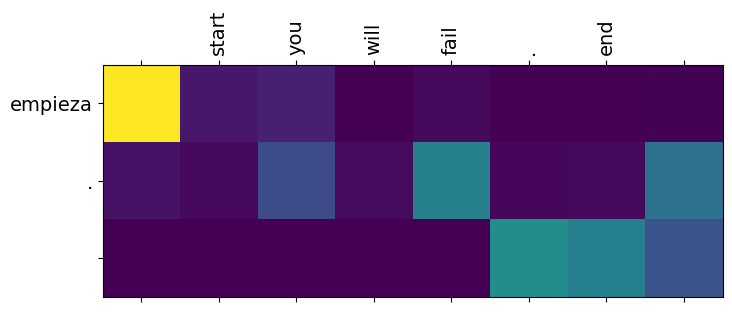

--------------------------------------------------
English (Input):    <start> that is mine . <end>
Spanish (Target):   eso es mio .
Input:  start that is mine . end 
Predicted translation: a ese es de el . 


C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)


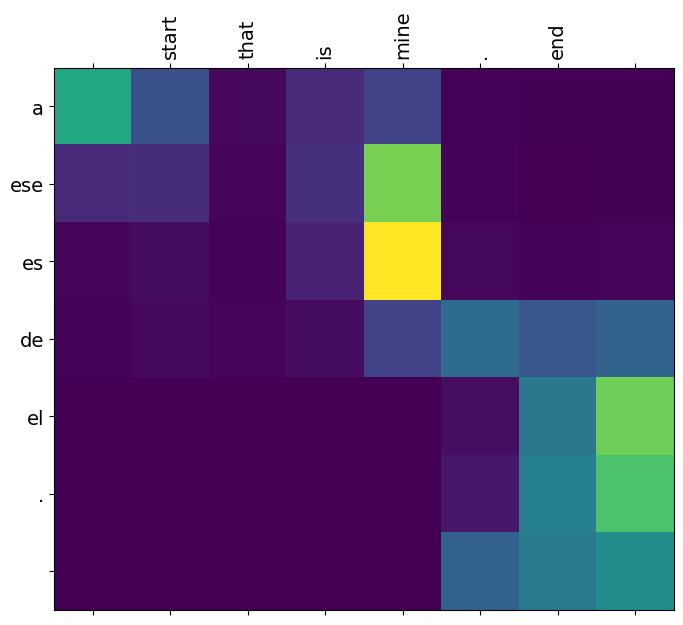

--------------------------------------------------
English (Input):    <start> tom is correct . <end>
Spanish (Target):   tom tiene razon .
Input:  start tom is correct . end 
Predicted translation: tom esta enamorado . 


C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)


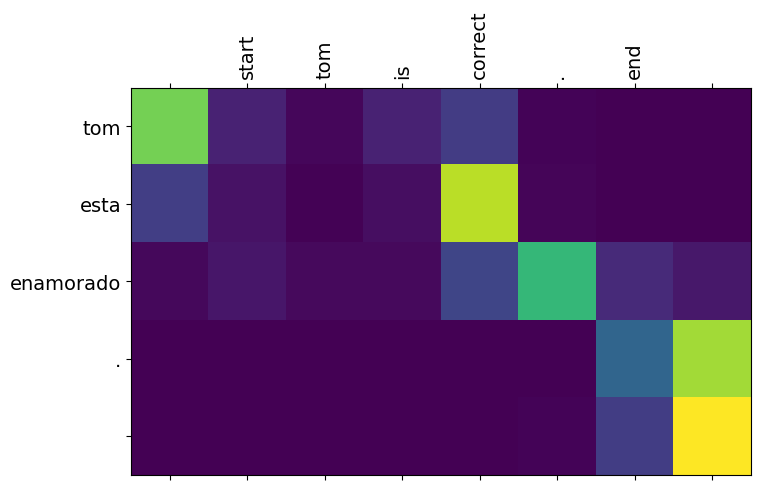

--------------------------------------------------
English (Input):    <start> i m still here . <end>
Spanish (Target):   todavia estoy aqui .
Input:  start i m still here . end 
Predicted translation: estoy aqui . 


C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)


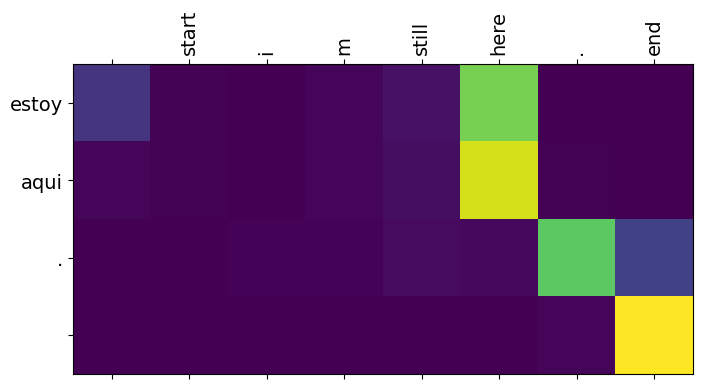

--------------------------------------------------
English (Input):    <start> i can t dance . <end>
Spanish (Target):   yo no puedo bailar .
Input:  start i can t dance . end 
Predicted translation: no te voy . 


C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + sentence, fontdict=fontdict, rotation=90)
C:\Users\phdst\AppData\Local\Temp\ipykernel_75216\3483938718.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + predicted_sentence, fontdict=fontdict)


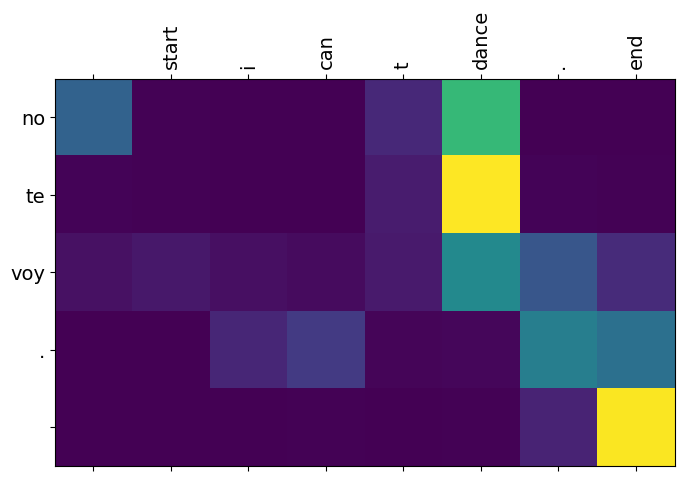

--------------------------------------------------


In [26]:
import random

print("--- Evaluating Test Samples with Attention Heatmaps ---")

# Pick a few random indices from your validation dataset
sample_indices = random.sample(range(len(input_tensor_val)), 5) # Let's do 5 so it doesn't open too many plots at once!

for idx in sample_indices:
    # 1. Reconstruct English input sentence
    inp_sentence = ' '.join([input_tokenizer.index_word[i] for i in input_tensor_val[idx] if i != 0])
    
    # 2. Reconstruct reference Spanish translation
    targ_tokens = [target_tokenizer.index_word[i] for i in target_tensor_val[idx] if i != 0 and target_tokenizer.index_word[i] not in ['<start>', '<end>']]
    
    print(f"English (Input):    {inp_sentence}")
    print(f"Spanish (Target):   {' '.join(targ_tokens)}")
    
    # 3. Run evaluation, print prediction, and generate the attention heatmap plot
    translate_and_plot(inp_sentence)
    
    print("-" * 50)

## Step 11: Calculating BLEU Scores for Test SamplesWe can use Python's nltk library to compute the sentence-level BLEU score alongside our side-by-side text evaluation.   

In [17]:
import random
from nltk.translate.bleu_score import sentence_bleu

print("--- Evaluating 10 Test Samples with BLEU Scores ---")

sample_indices = random.sample(range(len(input_tensor_val)), 10)
total_bleu = 0.0

for idx in sample_indices:
    # 1. Reconstruct English input sentence
    inp_sentence = ' '.join([input_tokenizer.index_word[i] for i in input_tensor_val[idx] if i != 0])
    
    # 2. Reconstruct reference Spanish translation (stripping tokens)
    targ_tokens = [target_tokenizer.index_word[i] for i in target_tensor_val[idx] if i != 0 and target_tokenizer.index_word[i] not in ['<start>', '<end>']]
    
    # 3. Run model evaluation
    predicted_result, _ = evaluate(inp_sentence)
    pred_tokens = predicted_result.strip().split()
    
    # 4. Compute BLEU score for this sentence (NLTK requires references as a list of lists)
    score = sentence_bleu([targ_tokens], pred_tokens)
    total_bleu += score
    
    print(f"English (Input):    {inp_sentence}")
    print(f"Spanish (Target):   {' '.join(targ_tokens)}")
    print(f"Spanish (Predicted): {predicted_result.strip()}")
    print(f"BLEU Score:         {score:.4f}")
    print("-" * 50)

print(f"\nAverage BLEU Score across sample: {total_bleu / len(sample_indices):.4f}")

--- Evaluating 10 Test Samples with BLEU Scores ---
English (Input):    <start> you said it ! <end>
Spanish (Target):   asi ! exactamente asi .
Spanish (Predicted): actua !
BLEU Score:         0.0000
--------------------------------------------------


C:\Users\phdst\anaconda3\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\phdst\anaconda3\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\phdst\anaconda3\Lib\site-packages\nltk\translate\bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnin

English (Input):    <start> i don t smoke . <end>
Spanish (Target):   no fumo .
Spanish (Predicted): no ronco .
BLEU Score:         0.0000
--------------------------------------------------
English (Input):    <start> it s not true . <end>
Spanish (Target):   no es verdad .
Spanish (Predicted): no es verdad .
BLEU Score:         1.0000
--------------------------------------------------
English (Input):    <start> tom arrived . <end>
Spanish (Target):   tom llego .
Spanish (Predicted): empieza a tomas .
BLEU Score:         0.0000
--------------------------------------------------
English (Input):    <start> tom says hello . <end>
Spanish (Target):   tom dice hola .
Spanish (Predicted): tom se ha ido .
BLEU Score:         0.0000
--------------------------------------------------
English (Input):    <start> i ll stay here . <end>
Spanish (Target):   me voy a quedar aca .
Spanish (Predicted): yo te voy a morir .
BLEU Score:         0.0000
--------------------------------------------------
